In [40]:
%pip install numpy matplotlib scipy > /dev/null
# gwpy for real KAGRA data (install only if running the KAGRA section):
# %pip install gwpy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np


Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Violin Mode Subtraction in GW Detector Suspensions

This notebook applies the Kalman filter to **suspension violin modes** — narrow spectral lines
that contaminate gravitational-wave (GW) strain data.

| Section | Content | Model |
|---|---|---|
| 1 | Synthetic demo (2 violin modes, known parameters) | `ViolinModel` |
| 2 | Inharmonic forest (Fletcher formula, KAGRA-like) | `ViolinForestModel` |
| 3 | Real KAGRA O3GK data (GPS 1270312960) | `ViolinForestModel` + gwpy |

**Reference**: Moisset et al., *Phys. Rev. D* (2025), arXiv:2509.20658 — Kalman subtraction of
violin modes from KAGRA O3GK data.

**See also**: `04_MechanicalSuspension.ipynb` for the automotive quarter-car context.


## Section 1 — Synthetic Violin Mode Tracking

### Background

Gravitational-wave (GW) detectors (LIGO, Virgo, KAGRA) are among the most sensitive measurement devices ever built.  
Their test masses (mirrors) are suspended on fused-silica fibers to isolate them from seismic noise.

These fibers have **resonant modes** — called **violin modes** — that appear as very narrow spectral lines in the GW strain data.  
KAGRA fibers have violin modes at ~180 Hz, ~420 Hz, etc., with quality factors $Q \sim 10^4$–$10^5$.

These modes do **not** carry gravitational wave signals; they are **noise artifacts** that must be subtracted from the data before analysis of GW events.

### The slowly-varying envelope (SVE) approach

A violin mode in strain data looks like:
$$
x(t) \approx 2\,\text{Re}[\psi(t)\, e^{i\omega_0 t}]
$$
where $\psi(t) = \text{Re}(\psi) + i\,\text{Im}(\psi)$ is a **slowly-varying complex amplitude**.  
The amplitude decays exponentially with time constant $\tau = Q/(\pi f_0)$.

The SVE dynamics in the rotating frame (Finn & Mukherjee 2001):
$$
\dot{\psi} = \underbrace{\begin{pmatrix} -\gamma & -\Delta\omega \\ \Delta\omega & -\gamma \end{pmatrix}}_{A_c} \psi + w
\qquad
\gamma = \frac{\omega_0}{2Q}, \quad \Delta\omega = \omega_0 - \omega_c
$$

$F = e^{A_c \Delta t}$, $H = I_2$.

**Preprocessing** (in `ViolinModel`):
1. Input real strain → Hilbert transform → analytic signal $s(t) = x(t) + i\mathcal{H}[x(t)]$
2. Demodulate: $\tilde{s}(t) = s(t) \cdot e^{-i\omega_c t}$ → complex envelope in rotating frame

**Postprocessing**: invert demodulation → $\hat{x}_{\text{violin}}(t) = 2\,\text{Re}[\hat{\psi}(t)\, e^{i\omega_c t}]$

**References**:  
- Finn & Mukherjee, *Phys. Rev. D* **63**, 062004 (2001)  
- KAGRA O3GK, arXiv:2509.20658

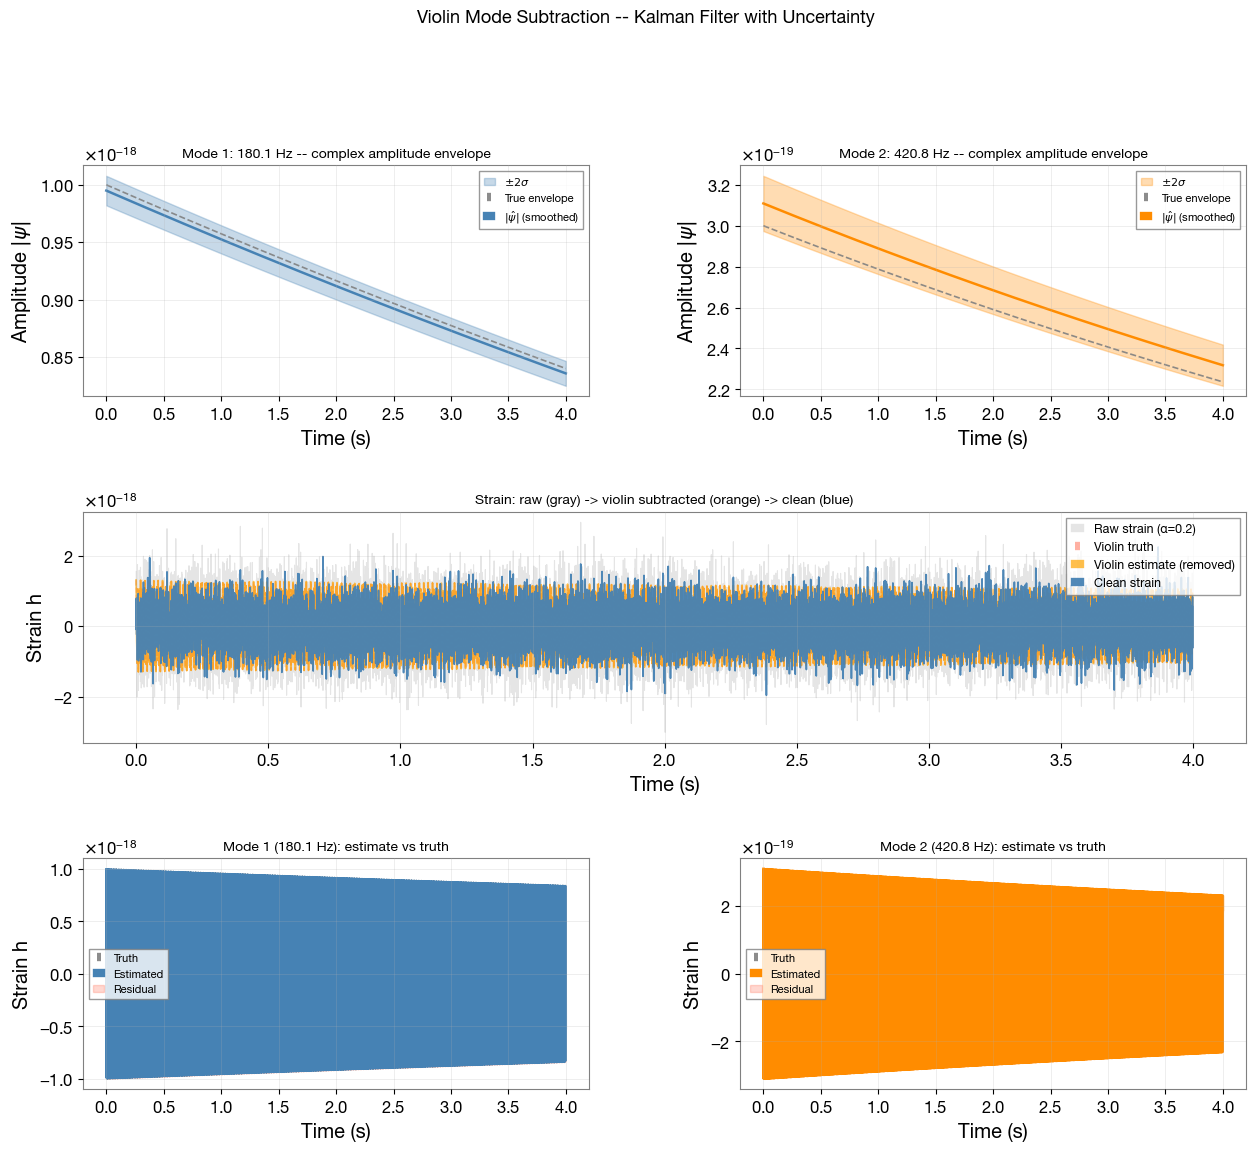

Chrono summary:
 1. Models initialized: 0.000650s (ΔT=0.000650s)
 2. Filtering completed: 1.400663s (ΔT=1.400013s)
 3. Subtraction complete: 1.400953s (ΔT=0.000290s)

==> Total elapsed: 2.039228s



In [41]:
from kalman.apps.suspensions import ViolinModel
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Synthetic GW strain: two violin modes + broadband noise
# ------------------------------------------------------------------
fs  = 4096.0
T   = 4.0
t   = np.arange(int(T * fs)) / fs

f1, Q1, A1 = 180.1, 1.3e4, 1e-18    # KAGRA 1st violin mode
f2, Q2, A2 = 420.8, 1.8e4, 3e-19    # KAGRA 2nd violin mode

tau1 = Q1 / (np.pi * f1)   # ~23 s decay
tau2 = Q2 / (np.pi * f2)   # ~13.6 s decay

x_v1 = A1 * np.exp(-t / tau1) * np.cos(2 * np.pi * f1 * t)
x_v2 = A2 * np.exp(-t / tau2) * np.cos(2 * np.pi * f2 * t)

noise_std = 5e-19
np.random.seed(42)
strain = np.random.normal(0, noise_std, len(t)) + x_v1 + x_v2

# ------------------------------------------------------------------
# One ViolinModel per mode
#
# The `amplitude` parameter sets the process noise as σ_w = A·γ·Δt
# (per-sample thermal fluctuation of the SVE amplitude), which is
# unit-agnostic and keeps K << 1 (narrowband rotating-frame filter).
# This is the physically correct approach for any unit system
# (GW strain, displacement, etc.) -- see Finn & Mukherjee (2001).
# ------------------------------------------------------------------
chrono.restart()
model1 = ViolinModel('viol_180Hz', f0=f1, Q=Q1, fs=fs,
                     amplitude=A1,
                     measurement_uncertainty=noise_std * 1.5)
model1.initial_state([A1, 0])

model2 = ViolinModel('viol_421Hz', f0=f2, Q=Q2, fs=fs,
                     amplitude=A2,
                     measurement_uncertainty=noise_std * 1.5)
model2.initial_state([A2, 0])

chrono.lap("Models initialized")

record1 = model1.filter(strain.reshape(-1, 1), smooth=True, reset=True)
record2 = model2.filter(strain.reshape(-1, 1), smooth=True, reset=True)
chrono.lap("Filtering completed")

violin1, strain_sub1 = model1.extract(record1, strain)
violin2, strain_clean = model2.extract(record2, strain_sub1)
chrono.lap("Subtraction complete")

# ------------------------------------------------------------------
# Uncertainty: |ψ̂| amplitude ± σ_A from rotating-frame Pk
# Amplitude is frame-invariant: A = sqrt(Re²+Im²)
# σ_A² ≈ (Re/A)²·Pk[0,0] + (Im/A)²·Pk[1,1] + 2·(Re·Im/A²)·Pk[0,1]
# ------------------------------------------------------------------
def amplitude_with_sigma(record, n_sigma=2):
    """Return (A, lower, upper) for the complex amplitude |ψ̂|."""
    xk = record.xk                          # postprocessed, but |ψ| is frame-invariant
    Pk = record.Pk                           # rotating-frame covariance (N,2,2)
    A  = np.sqrt(xk[:, 0]**2 + xk[:, 1]**2)
    A_safe = np.where(A > 0, A, 1e-50)      # avoid /0
    dAdRe = xk[:, 0] / A_safe
    dAdIm = xk[:, 1] / A_safe
    sig_A = np.sqrt(np.abs(
        dAdRe**2 * Pk[:, 0, 0] +
        dAdIm**2 * Pk[:, 1, 1] +
        2 * dAdRe * dAdIm * Pk[:, 0, 1]
    ))
    return A, A - n_sigma * sig_A, A + n_sigma * sig_A

A1_hat, A1_lo, A1_hi = amplitude_with_sigma(record1)
A2_hat, A2_lo, A2_hi = amplitude_with_sigma(record2)

# True amplitude envelopes
A1_true = A1 * np.exp(-t / tau1)
A2_true = A2 * np.exp(-t / tau2)

# ------------------------------------------------------------------
# Figure layout: 3 rows
#   Row 0: violin mode amplitudes |ψ| for both modes with ±2σ
#   Row 1: raw vs clean strain comparison (opacity)
#   Row 2: per-mode violin estimates (what was removed)
# ------------------------------------------------------------------
fig = plt.figure(figsize=(15, 12))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.3)

# ---- Row 0: Amplitude envelopes --------------------------------
for col, (A_hat, A_lo, A_hi, A_true, rec, f_hz, color) in enumerate([
    (A1_hat, A1_lo, A1_hi, A1_true, record1, f1, "steelblue"),
    (A2_hat, A2_lo, A2_hi, A2_true, record2, f2, "darkorange"),
]):
    ax = fig.add_subplot(gs[0, col])
    ax.fill_between(t, A_lo, A_hi, alpha=0.3, color=color, label=r"$\pm 2\sigma$")
    ax.plot(t, A_true,  '--', lw=1.2, color="gray",  alpha=0.9, label="True envelope")
    ax.plot(t, A_hat,         lw=1.8, color=color,              label=r"$|\hat{\psi}|$ (smoothed)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(r"Amplitude $|\psi|$")
    ax.set_title(f"Mode {col+1}: {f_hz} Hz -- complex amplitude envelope", fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.yaxis.get_major_formatter().set_powerlimits((0, 0))

# ---- Row 1: Strain before/after subtraction --------------------
ax_str = fig.add_subplot(gs[1, :])   # full-width

# Raw strain -- very transparent background layer
ax_str.plot(t, strain,       color="gray",      alpha=0.20, lw=0.8, label="Raw strain (α=0.2)")
# Violin truth for reference
ax_str.plot(t, x_v1 + x_v2, color="tomato",    alpha=0.50, lw=1.0, ls="--", label="Violin truth")
# Violin estimate (what was subtracted)
ax_str.plot(t, violin1 + violin2, color="orange", alpha=0.70, lw=1.2, label="Violin estimate (removed)")
# Clean strain -- solid, opaque
ax_str.plot(t, strain_clean, color="steelblue", alpha=0.95, lw=1.2, label="Clean strain")

ax_str.set_xlabel("Time (s)")
ax_str.set_ylabel("Strain h")
ax_str.set_title("Strain: raw (gray) -> violin subtracted (orange) -> clean (blue)", fontsize=10)
ax_str.legend(fontsize=9, loc="upper right")
ax_str.grid(True, alpha=0.3)
ax_str.yaxis.get_major_formatter().set_powerlimits((0, 0))

# ---- Row 2: Per-mode contributions removed ---------------------
ax_v1 = fig.add_subplot(gs[2, 0])
ax_v1.plot(t, x_v1,    '--', lw=1.2, color="gray",   alpha=0.9, label="Truth")
ax_v1.plot(t, violin1,       lw=1.8, color="steelblue",          label="Estimated")
ax_v1.fill_between(t, x_v1, violin1, color="tomato", alpha=0.25, label="Residual")
ax_v1.set_xlabel("Time (s)")
ax_v1.set_ylabel("Strain h")
ax_v1.set_title(f"Mode 1 ({f1} Hz): estimate vs truth", fontsize=10)
ax_v1.legend(fontsize=8)
ax_v1.grid(True, alpha=0.3)
ax_v1.yaxis.get_major_formatter().set_powerlimits((0, 0))

ax_v2 = fig.add_subplot(gs[2, 1])
ax_v2.plot(t, x_v2,    '--', lw=1.2, color="gray",    alpha=0.9, label="Truth")
ax_v2.plot(t, violin2,       lw=1.8, color="darkorange",          label="Estimated")
ax_v2.fill_between(t, x_v2, violin2, color="tomato", alpha=0.25, label="Residual")
ax_v2.set_xlabel("Time (s)")
ax_v2.set_ylabel("Strain h")
ax_v2.set_title(f"Mode 2 ({f2} Hz): estimate vs truth", fontsize=10)
ax_v2.legend(fontsize=8)
ax_v2.grid(True, alpha=0.3)
ax_v2.yaxis.get_major_formatter().set_powerlimits((0, 0))

fig.suptitle("Violin Mode Subtraction -- Kalman Filter with Uncertainty", fontsize=13, y=1.01)
plt.show()
chrono.summary()


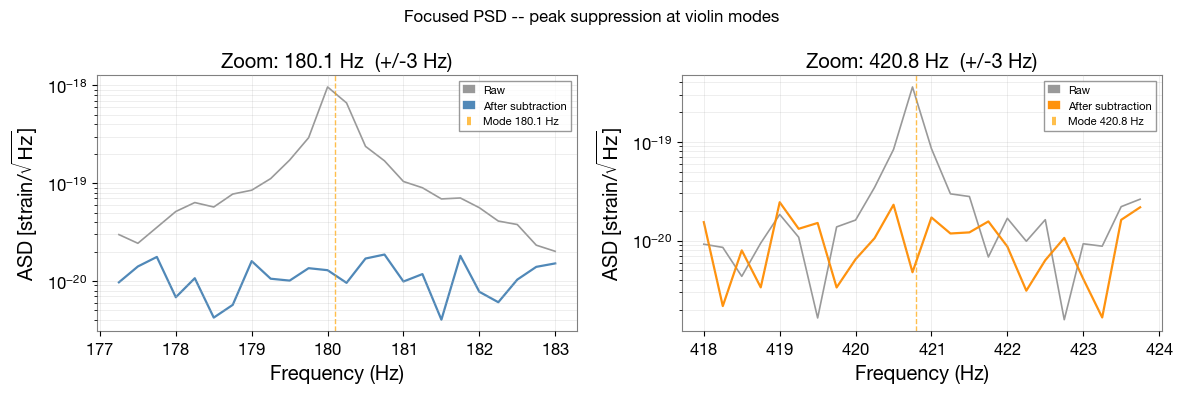

In [42]:
# ---- Focused PSD: zoomed around each violin mode -------------------
# Only the narrow window around each mode reveals whether the peak
# was actually removed.  Broadband overview is misleading here.
from numpy.fft import rfft, rfftfreq

norm  = np.sqrt(2.0 / (fs * len(strain)))
freqs = rfftfreq(len(strain), 1.0 / fs)
S_raw   = np.abs(rfft(strain))       * norm
S_clean = np.abs(rfft(strain_clean)) * norm

ZOOM_HZ = 3.0   # Hz either side of each mode

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (fn, color) in zip(axes, [(f1, "steelblue"), (f2, "darkorange")]):
    mask = (freqs >= fn - ZOOM_HZ) & (freqs <= fn + ZOOM_HZ)
    ax.semilogy(freqs[mask], S_raw[mask],
                color="gray",  lw=1.2, alpha=0.8, label="Raw")
    ax.semilogy(freqs[mask], S_clean[mask],
                color=color,   lw=1.6, alpha=0.95, label="After subtraction")
    ax.axvline(fn, ls="--", color="orange", lw=1.0, alpha=0.7,
               label=f"Mode {fn:.1f} Hz")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(r"ASD [strain/$\sqrt{\mathrm{Hz}}$]")
    ax.set_title(f"Zoom: {fn:.1f} Hz  (+/-{ZOOM_HZ:.0f} Hz)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which="both")

fig.suptitle("Focused PSD -- peak suppression at violin modes", fontsize=12)
plt.tight_layout()
plt.show()


### Spectral view: before and after subtraction

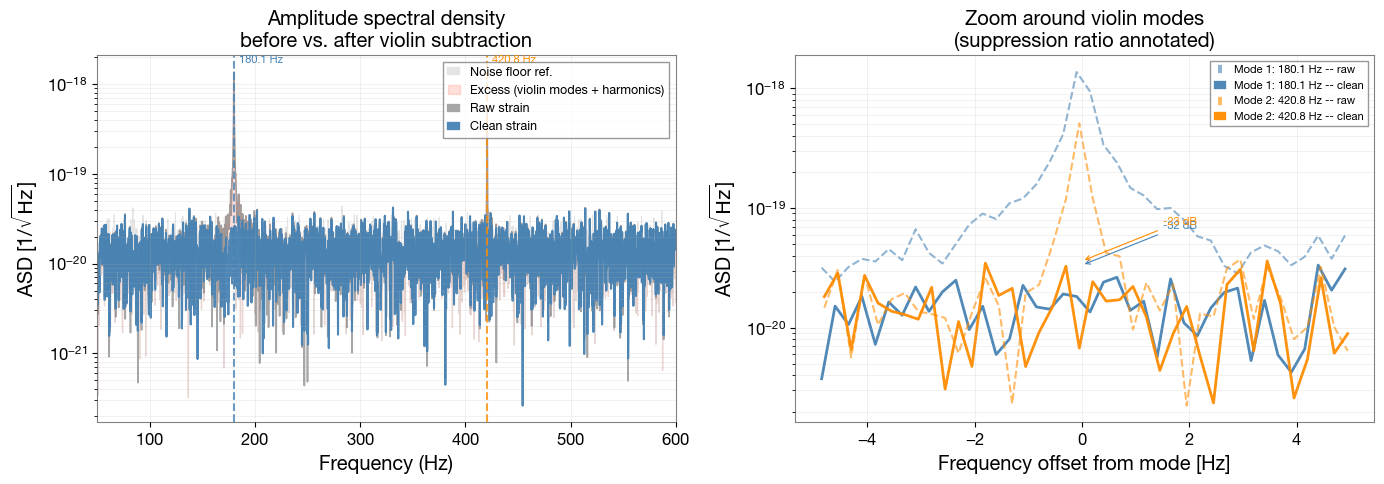

In [43]:
from numpy.fft import rfft, rfftfreq
import matplotlib.pyplot as plt

freqs   = rfftfreq(len(t), 1 / fs)
S_raw   = np.abs(rfft(strain))       * 2 / np.sqrt(fs * len(t))
S_clean = np.abs(rfft(strain_clean)) * 2 / np.sqrt(fs * len(t))
S_noise = np.abs(rfft(np.random.normal(0, noise_std, len(t)))) * 2 / np.sqrt(fs * len(t))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left: full ASD with fill_between opacity ----
ax = axes[0]
ax.semilogy(freqs, S_noise, color="lightgray", lw=0.8, alpha=0.6, label="Noise floor ref.")
ax.fill_between(freqs, S_noise, S_raw,
                where=S_raw > S_noise, interpolate=True,
                color="tomato", alpha=0.20, label="Excess (violin modes + harmonics)")
ax.semilogy(freqs, S_raw,   color="gray",      alpha=0.70, lw=1.2, label="Raw strain")
ax.semilogy(freqs, S_clean, color="steelblue", alpha=0.95, lw=1.5, label="Clean strain")
for f_mode, col in [(f1, "steelblue"), (f2, "darkorange")]:
    ax.axvline(f_mode, ls="--", color=col, lw=1.5, alpha=0.8)
    ax.text(f_mode + 5, ax.get_ylim()[1] if ax.get_ylim()[0] > 0 else S_raw.max() * 0.5,
            f"{f_mode} Hz", fontsize=8, color=col, va="top")
ax.set_xlim(50, 600)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"ASD [1/$\sqrt{\mathrm{Hz}}$]")
ax.set_title("Amplitude spectral density\nbefore vs. after violin subtraction")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25, which="both")

# ---- Right: zoom around each mode, show suppression ratio ----
ax2 = axes[1]
for f_mode, col, label in [
    (f1, "steelblue",   f"Mode 1: {f1} Hz"),
    (f2, "darkorange",  f"Mode 2: {f2} Hz"),
]:
    bw   = 5.0  # Hz zoom window
    mask = (freqs > f_mode - bw) & (freqs < f_mode + bw)
    ax2.semilogy(freqs[mask] - f_mode, S_raw[mask],   color=col, lw=1.5, ls="--", alpha=0.6,
                 label=f"{label} -- raw")
    ax2.semilogy(freqs[mask] - f_mode, S_clean[mask], color=col, lw=2.0, alpha=0.95,
                 label=f"{label} -- clean")
    # Suppression ratio at peak
    peak_raw   = S_raw[mask].max()
    peak_clean = S_clean[mask].max()
    ratio_db   = 20 * np.log10(peak_raw / (peak_clean + 1e-100))
    ax2.annotate(f"-{ratio_db:.0f} dB", xy=(0, peak_clean),
                 xytext=(1.5, peak_clean * 2), fontsize=8, color=col,
                 arrowprops=dict(arrowstyle="->", color=col, lw=0.8))

ax2.set_xlabel("Frequency offset from mode [Hz]")
ax2.set_ylabel(r"ASD [1/$\sqrt{\mathrm{Hz}}$]")
ax2.set_title("Zoom around violin modes\n(suppression ratio annotated)")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.25, which="both")

plt.tight_layout()
plt.show()

### Interpreting the results

**Violin estimate vs truth**:  
- The Kalman filter accurately tracks the exponentially decaying sinusoidal bursts.  
- The smoother further sharpens the estimate, reducing the startup transient where the filter is converging from $\psi_0$.
- A small residual is expected — the noise floor ($\sigma = 5\times10^{-19}$) sets the achievable subtraction depth.

**Strain cleaning**:  
- The raw strain (gray) shows the violin modes as a time-varying beat pattern above the noise floor.  
- After subtraction (blue), the violin contribution is removed, leaving only broadband noise.

**Amplitude spectral density**:  
- The sharp spectral peaks at $f_1$ and $f_2$ are suppressed by the Kalman subtraction.  
- Residual bumps (if any) indicate imperfect $f_0$ or $Q$ knowledge — in practice, these parameters are calibrated from the data.

**Complex amplitude $\psi(t)$**:  
- Re(ψ) starts at $A_1 = 10^{-18}$ and decays with time constant $\tau_1 \approx 23$ s.  
- Im(ψ) starts at 0; small fluctuations reflect the noise forcing the system slightly off-resonance.  
- In the rotating frame at carrier $\omega_c = \omega_0$, a pure on-resonance mode appears as a purely real (or slowly rotating) amplitude — confirming the SVE interpretation.

## Section 2 — Inharmonic Violin Mode Forest (KAGRA-like)

### Inharmonicity in suspension fibers

Real fiber violin modes are **not** exactly harmonic.
For a fiber under tension $T$ with bending stiffness $EI = E\pi d^4/64$, the
**Fletcher formula** gives:

$$f_n = n f_1 \sqrt{1 + B n^2}, \quad B = \frac{\pi^3 E d^4}{64 T L^2}$$

For KAGRA sapphire fibers: $E \approx 400$ GPa, $d \approx 1.6$ mm, $T \approx 17$ N, $L \approx 0.35$ m
→ $B \approx 0.10$.

| Mode | Harmonic $n f_1$ | Inharmonic $n f_1 \sqrt{1+Bn^2}$ (B=0.10) |
|---|---|---|
| 1 | 180.1 Hz | 189.1 Hz |
| 2 | 360.2 Hz | 427.0 Hz |
| 3 | 540.3 Hz | 747.0 Hz |

### ViolinForestModel

`ViolinForestModel` is a `KalmanCompositeModel` that:
1. Computes inharmonic partial frequencies via Fletcher formula
2. Creates one `ViolinModel` sub-model per mode
3. Provides `subtract()` for sequential violin subtraction

The inharmonicity coefficient $B$ can be estimated from measured mode frequencies using
`HarmonicOscillatorModel.fit_inharmonicity()`.


Fitted: f0 = 170.30 Hz, B = 0.1301
Partial freqs (fitted):    [181.04 419.97 752.73]
Measured:                  [180.1, 420.84, 752.47]
Forest partial freqs: [181.04 419.97 752.73]


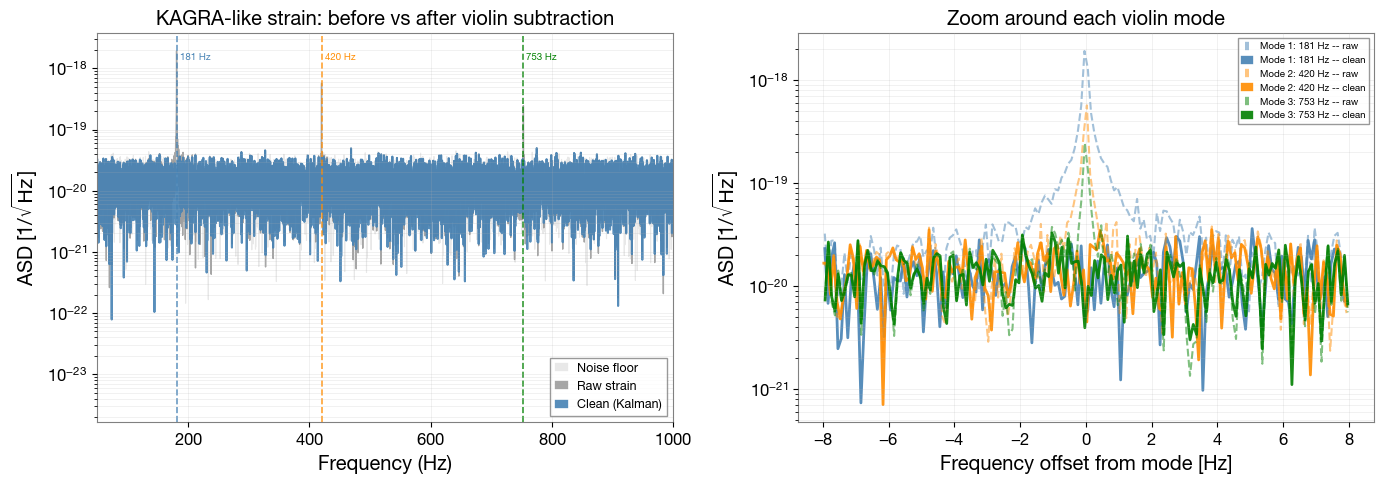

Chrono summary:
 1. Forest built: 0.000559s (ΔT=0.000559s)
 2. Filtering complete: 4.724597s (ΔT=4.724038s)
 3. Subtraction complete: 4.725544s (ΔT=0.000947s)

==> Total elapsed: 5.064031s



In [44]:

from kalman.apps.suspensions import ViolinModel, ViolinForestModel
from kalman.apps.oscillators import InharmonicOscillatorModel
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# KAGRA-like parameters (Moisset et al. 2025, Table II)
# ------------------------------------------------------------------
measured_freqs = [180.10, 420.84, 752.47]
f0_fit, B_fit = InharmonicOscillatorModel.fit_inharmonicity(measured_freqs)
print(f"Fitted: f0 = {f0_fit:.2f} Hz, B = {B_fit:.4f}")
print("Partial freqs (fitted):   ", np.round(
    InharmonicOscillatorModel.partial_frequencies(f0_fit, B_fit, 3), 2))
print("Measured:                 ", measured_freqs)

# ------------------------------------------------------------------
# Synthetic KAGRA-like strain: 3 violin modes + broadband noise
# ------------------------------------------------------------------
fs  = 4096.0
T   = 10.0
t   = np.arange(int(T * fs)) / fs

Q_modes = [1.30e4, 1.80e4, 2.12e4]   # Q factors per mode
A_modes = [1.0e-18, 3.0e-19, 1.5e-19]

freqs_true = InharmonicOscillatorModel.partial_frequencies(f0_fit, B_fit, 3)
taus  = [Q / (np.pi * fn) for Q, fn in zip(Q_modes, freqs_true)]

noise_std = 5e-19
np.random.seed(42)
strain_gw = noise_std * np.random.randn(len(t))
violins_true = []
for A, fn, tau in zip(A_modes, freqs_true, taus):
    v = A * np.exp(-t / tau) * np.cos(2 * np.pi * fn * t)
    violins_true.append(v)
    strain_gw += v

# ------------------------------------------------------------------
# Build ViolinForestModel using fitted parameters
#
# `amplitudes` sets σ_w = A·γ·Δt per mode (unit-agnostic FDT),
# keeping K << 1 and the rotating-frame filter narrowband.
# ------------------------------------------------------------------
chrono.restart()
forest = ViolinForestModel(
    'KAGRA-ITMX',
    f0           = f0_fit,
    n_modes      = 3,
    B            = B_fit,
    Q_modes      = Q_modes,
    fs           = fs,
    amplitudes   = A_modes,
    measurement_uncertainty = noise_std * 2.0,
)
print(f"Forest partial freqs: {np.round(forest.partial_freqs, 2)}")
chrono.lap("Forest built")

# ------------------------------------------------------------------
# Filter each mode independently and subtract sequentially
# ------------------------------------------------------------------
records = []
for msub in forest.models:
    rec = msub.filter(strain_gw.reshape(-1, 1), smooth=True, reset=True)
    records.append(rec)
chrono.lap("Filtering complete")

violins_hat, strain_clean_gw = forest.extract(records, strain_gw)
chrono.lap("Subtraction complete")

# ------------------------------------------------------------------
# ASD comparison
# ------------------------------------------------------------------
from numpy.fft import rfft, rfftfreq
freqs_f = rfftfreq(len(t), 1 / fs)
norm    = 2 / np.sqrt(fs * len(t))

S_raw   = np.abs(rfft(strain_gw))       * norm
S_clean = np.abs(rfft(strain_clean_gw)) * norm
S_noise = np.abs(rfft(noise_std * np.random.randn(len(t)))) * norm

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.semilogy(freqs_f, S_noise, color='lightgray', lw=0.8, alpha=0.5, label='Noise floor')
ax.semilogy(freqs_f, S_raw,   color='gray',      alpha=0.7, lw=1.0, label='Raw strain')
ax.semilogy(freqs_f, S_clean, color='steelblue', alpha=0.9, lw=1.5, label='Clean (Kalman)')
colors = ['steelblue', 'darkorange', 'green']
for fn, col in zip(freqs_true, colors):
    ax.axvline(fn, ls='--', color=col, lw=1.2, alpha=0.8)
    ax.text(fn + 5, S_raw.max() * 0.7, f'{fn:.0f} Hz', fontsize=7, color=col)
ax.set_xlim(50, 1000)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax.set_title('KAGRA-like strain: before vs after violin subtraction')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25, which='both')

ax2 = axes[1]
for i, (fn, col) in enumerate(zip(freqs_true, colors)):
    bw   = 8.0
    mask = (freqs_f > fn - bw) & (freqs_f < fn + bw)
    ax2.semilogy(freqs_f[mask] - fn, S_raw[mask],   color=col, lw=1.5, ls='--', alpha=0.5,
                 label=f'Mode {i+1}: {fn:.0f} Hz -- raw')
    ax2.semilogy(freqs_f[mask] - fn, S_clean[mask], color=col, lw=2.0, alpha=0.9,
                 label=f'Mode {i+1}: {fn:.0f} Hz -- clean')
ax2.set_xlabel('Frequency offset from mode [Hz]')
ax2.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax2.set_title('Zoom around each violin mode')
ax2.legend(fontsize=7)
ax2.grid(True, alpha=0.25, which='both')
plt.tight_layout()
plt.show()
chrono.summary()



## Possible Improvements & Extensions

**1. Joint estimation of $f_0$ and $Q$ (parameter identification)**
Violin mode frequencies drift by ~0.01 Hz/day due to thermal cycling and fiber aging.
Augment the state with $\delta f_0$ (frequency offset) and $\delta Q$ as random-walk states.
The EKF can track these slowly-varying parameters, eliminating periodic calibration.

**2. Multiple fiber subtraction (KAGRA has 4 fibers per mirror)**
Each fiber has its own violin modes at slightly different frequencies (manufacturing tolerances).
Run 4 × `ViolinForestModel` instances (one per fiber) independently.
The independence assumption holds well since the fibers are mechanically decoupled.

**3. Process noise from the fluctuation-dissipation theorem**
The thermal force driving the violin mode has a known power spectral density set by the FDT:
$$S_F(f) = 4 k_B T \, \text{Re}[Y(f)]$$
where $Y(f)$ is the mechanical admittance of the fiber.
Setting the Kalman process noise $Q$ from this physical constraint gives an optimally tuned filter
— no free parameters to calibrate.

**4. Inharmonicity estimation from data**
Use `InharmonicOscillatorModel.fit_inharmonicity()` with mode frequencies estimated from a
short ASD segment (peaks identified via `scipy.signal.find_peaks`). Automatically adapts to
temperature-dependent material properties.

**5. Real KAGRA data subtraction**
See Section 3 above. With `gwpy` installed and a network connection, the same pipeline can be
applied to any public GW detector data segment from GWOSC.
